# FairLend-ASP: Report 2 implementation

**Teutan Stefan, ICA2** - Declarative Programming in Machine Learning

This notebook implements the mortgage approval system from Report 1 on real HMDA data for
Delaware (2022 for training, 2023 for testing). The notebook follows the plan from the report:

1. Data and its biases
2. Models: rule baseline, XGBoost (M1), small decision tree (M2)
3. Evaluation: accuracy, calibration, fairness, proxy test
4. **Feature A** - a fair decision policy chosen by clingo, with MUS explanations
5. **Feature B** - actionable recourse for denied applicants, computed by clingo
6. Results compared with the targets from Report 1

## 0. Setup
On Google Colab this cell installs the libraries and downloads the repository (data + ASP files).

In [1]:
import os, sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "clingo", "xgboost"], check=True)
    if not os.path.exists("asp/policy.lp"):
        subprocess.run(["git", "clone", "-q", "https://github.com/stefanteutan/fairlend-asp.git"], check=True)
        os.chdir("fairlend-asp")

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import clingo
import xgboost as xgb
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score

pd.set_option("display.width", 140)
SEED = 0
BLUE = "#2a78d6"

## 1. Data

HMDA reports almost every mortgage application in the US. I keep only applications with a final
decision: approved (`action_taken` 1 or 2) or denied (3). Withdrawn and incomplete files are dropped.
I also drop business loans, reverse mortgages and multifamily buildings, and applications without
DTI, LTV, income, property value or loan term.

In [3]:
DTI_BINS = {"<20%": 15, "20%-<30%": 25, "30%-<36%": 33, "50%-60%": 55, ">60%": 65}

def load(path):
    raw = pd.read_csv(path, low_memory=False)
    df = raw[raw.action_taken.isin([1, 2, 3])].copy()
    df["approved"] = (df.action_taken != 3).astype(int)
    df = df[(df.business_or_commercial_purpose == 2) & (df.reverse_mortgage == 2)
            & df.derived_dwelling_category.str.startswith("Single Family")]
    decided = df.copy()
    # DTI is published as ranges outside 36-49%; I use the middle of each range
    df["dti"] = df.debt_to_income_ratio.map(lambda v: DTI_BINS.get(v, v))
    for c in ["dti", "loan_to_value_ratio", "property_value", "loan_term"]:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    df = df.rename(columns={"loan_to_value_ratio": "ltv"})
    df = df.dropna(subset=["dti", "ltv", "income", "property_value", "loan_term"])
    df = df[(df.income > 0) & (df.ltv > 0) & (df.ltv <= 150)].copy()
    df["loan_amount_k"] = df.loan_amount / 1000
    df["property_value_k"] = df.property_value / 1000
    df["manufactured"] = df.derived_dwelling_category.str.contains("Manufactured").astype(int)
    df["open_end"] = (df["open-end_line_of_credit"] == 1).astype(int)
    df["second_lien"] = (df.lien_status == 2).astype(int)
    df["investment"] = (df.occupancy_type != 1).astype(int)
    for name, code in {"purpose_purchase": 1, "purpose_improvement": 2, "purpose_refi": 31,
                       "purpose_cashout": 32, "purpose_other": 4}.items():
        df[name] = (df.loan_purpose == code).astype(int)
    for name, code in {"loan_fha": 2, "loan_va": 3, "loan_usda": 4}.items():
        df[name] = (df.loan_type == code).astype(int)
    # demographic groups, used ONLY for auditing
    df["race"] = df.derived_race.map({"White": "White", "Black or African American": "Black",
                                      "Asian": "Asian", "Race Not Available": "Not available"}).fillna("Other")
    df["sex"] = df.derived_sex.map({"Male": "Male", "Female": "Female", "Joint": "Joint",
                                    "Sex Not Available": "Not available"})
    df["eth"] = df.derived_ethnicity.map({"Not Hispanic or Latino": "Not Hispanic",
                                          "Hispanic or Latino": "Hispanic"}).fillna("Other / n.a.")
    return raw, decided, df

FEATURES = ["loan_amount_k", "income", "dti", "ltv", "property_value_k", "loan_term", "manufactured",
            "open_end", "second_lien", "investment", "purpose_purchase", "purpose_improvement",
            "purpose_refi", "purpose_cashout", "purpose_other", "loan_fha", "loan_va", "loan_usda"]

raw22, dec22, train = load("data/hmda_DE_2022.csv")
raw23, dec23, test = load("data/hmda_DE_2023.csv")
print(f"2022: {len(raw22):,} records -> {len(dec22):,} decided -> {len(train):,} complete (training)")
print(f"2023: {len(raw23):,} records -> {len(dec23):,} decided -> {len(test):,} complete (test)")

2022: 62,038 records -> 40,593 decided -> 36,504 complete (training)
2023: 44,128 records -> 28,401 decided -> 25,768 complete (test)


### 1.1 Biases already visible in the data
The first table shows the historical approval rate by group. These are the lender decisions the
model learns from, which is the **label bias** from Report 1.

In [4]:
def group_table(df, col):
    t = df.groupby(col).approved.agg(applications="size", approval_rate="mean")
    return t.sort_values("applications", ascending=False).round(3)

for col in ["race", "sex", "eth"]:
    print(group_table(train, col), "\n")

               applications  approval_rate
race                                      
White                 22134          0.835
Black                  6247          0.714
Not available          5624          0.758
Asian                  1492          0.804
Other                  1007          0.795 

               applications  approval_rate
sex                                       
Joint                 12844          0.862
Male                  11461          0.769
Female                 9675          0.781
Not available          2524          0.701 

              applications  approval_rate
eth                                      
Not Hispanic         28770          0.811
Other / n.a.          5878          0.763
Hispanic              1856          0.754 



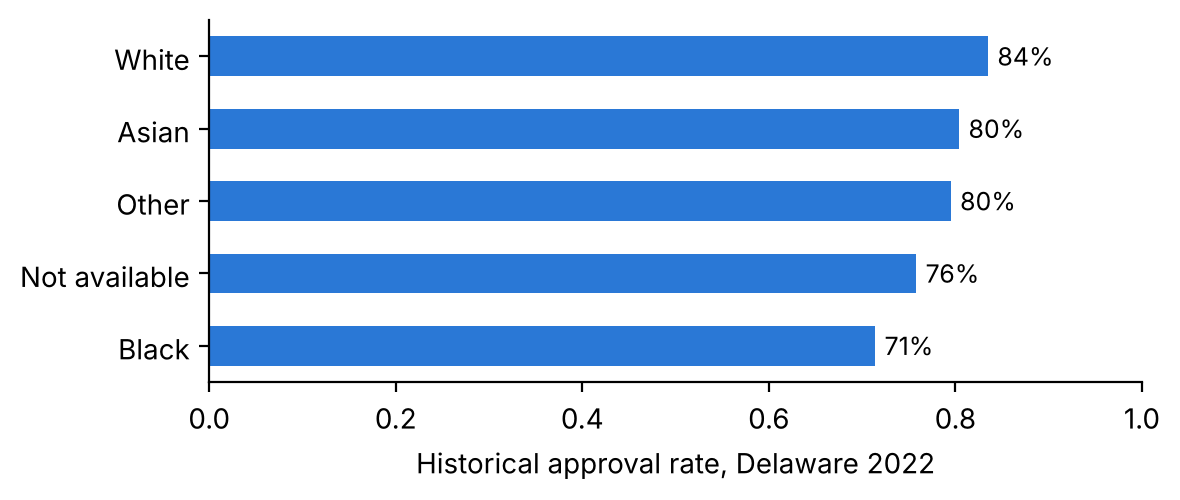

In [5]:
rates = group_table(train, "race").approval_rate.sort_values()
fig, ax = plt.subplots(figsize=(6, 2.6))
ax.barh(rates.index, rates.values, color=BLUE, height=0.55)
for i, v in enumerate(rates.values):
    ax.text(v + 0.01, i, f"{v:.0%}", va="center", fontsize=9)
ax.set_xlim(0, 1); ax.set_xlabel("Historical approval rate, Delaware 2022")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

### 1.2 Missing and inferred demographics, selection effect

In [6]:
na_race = (dec22.derived_race == "Race Not Available").mean()
na_sex = (dec22.derived_sex == "Sex Not Available").mean()
observed = (dec22.applicant_race_observed == 1).mean()
print(f"Race not available: {na_race:.1%}   Sex not available: {na_sex:.1%}")
print(f"Race recorded by visual observation or surname: {observed:.1%}")
kept = (train.groupby("race").size() / dec22.assign(race=dec22.derived_race.map(
    {"White": "White", "Black or African American": "Black", "Asian": "Asian",
     "Race Not Available": "Not available"}).fillna("Other")).groupby("race").size())
print("Share of decided applications that are complete enough to keep:\n", kept.round(3))
print(f"Approval rate before / after dropping incomplete files: "
      f"{dec22.approved.mean():.3f} / {train.approved.mean():.3f}")
print("Credit score is not published in HMDA, so the model never sees it.")

Race not available: 15.6%   Sex not available: 6.9%
Race recorded by visual observation or surname: 2.9%
Share of decided applications that are complete enough to keep:
 race
Asian            0.923
Black            0.867
Not available    0.890
Other            0.876
White            0.911
dtype: float64
Approval rate before / after dropping incomplete files: 0.762 / 0.800
Credit score is not published in HMDA, so the model never sees it.


## 2. Models
* **Baseline:** a fixed underwriting rule, approve if DTI <= 43% and LTV <= 95%.
* **M1:** XGBoost with monotonic constraints (higher DTI or LTV can never raise the score,
  higher income can never lower it).
* **M2:** a decision tree. Its depth is chosen with 5-fold cross-validation on 2022: the smallest
  depth whose AUC is within 3 points of M1.

In [7]:
X, y = train[FEATURES], train.approved
Xt, yt = test[FEATURES], test.approved
mono = {"dti": -1, "ltv": -1, "income": 1}
m1 = xgb.XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05, subsample=0.8,
                       monotone_constraints=tuple(mono.get(f, 0) for f in FEATURES),
                       eval_metric="auc", random_state=SEED)
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
cv_m1 = cross_val_score(m1, X, y, cv=cv, scoring="roc_auc").mean()
print(f"M1 cross-validation AUC: {cv_m1:.3f}")
cv_tree = {}
for depth in [3, 4, 5, 6]:
    t = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=100, random_state=SEED)
    cv_tree[depth] = cross_val_score(t, X, y, cv=cv, scoring="roc_auc").mean()
    print(f"tree depth {depth}: CV AUC {cv_tree[depth]:.3f}  gap to M1 {cv_m1 - cv_tree[depth]:.3f}")
DEPTH = next((d for d in cv_tree if cv_m1 - cv_tree[d] <= 0.03), max(cv_tree))
print("Chosen depth:", DEPTH)

M1 cross-validation AUC: 0.838
tree depth 3: CV AUC 0.765  gap to M1 0.072


tree depth 4: CV AUC 0.788  gap to M1 0.050


tree depth 5: CV AUC 0.801  gap to M1 0.037


tree depth 6: CV AUC 0.810  gap to M1 0.028
Chosen depth: 6


In [8]:
m1.fit(X, y)
m2 = DecisionTreeClassifier(max_depth=DEPTH, min_samples_leaf=100, random_state=SEED).fit(X, y)
p1, p2 = m1.predict_proba(Xt)[:, 1], m2.predict_proba(Xt)[:, 1]
rule = ((test.dti <= 43) & (test.ltv <= 95)).astype(int)
print(f"M2 has {m2.get_n_leaves()} leaves, so at most {DEPTH} conditions per explanation.")

def ece(y_true, p, bins=10):
    idx = np.minimum((p * bins).astype(int), bins - 1)
    return sum(abs(y_true[idx == b].mean() - p[idx == b].mean()) * (idx == b).mean()
               for b in range(bins) if (idx == b).any())

perf = pd.DataFrame({
    "AUC": [roc_auc_score(yt, rule), roc_auc_score(yt, p1), roc_auc_score(yt, p2)],
    "accuracy": [accuracy_score(yt, rule), accuracy_score(yt, p1 > .5), accuracy_score(yt, p2 > .5)],
    "F1 (deny class)": [f1_score(1 - yt, 1 - rule), f1_score(1 - yt, p1 <= .5), f1_score(1 - yt, p2 <= .5)],
    "ECE": [np.nan, ece(yt.values, p1), ece(yt.values, p2)],
}, index=["Baseline rule", "M1 XGBoost", "M2 tree"]).round(3)
print(perf)
print(f"\nTemporal drop for M2 (CV 2022 -> test 2023): {cv_tree[DEPTH] - perf.loc['M2 tree', 'AUC']:.3f} AUC")

M2 has 38 leaves, so at most 6 conditions per explanation.
                 AUC  accuracy  F1 (deny class)    ECE
Baseline rule  0.631     0.600            0.436    NaN
M1 XGBoost     0.863     0.863            0.614  0.007
M2 tree        0.835     0.853            0.561  0.019

Temporal drop for M2 (CV 2022 -> test 2023): -0.025 AUC


In [9]:
print(export_text(m2, feature_names=FEATURES, decimals=1)[:2500], "...")

|--- dti <= 60.0
|   |--- purpose_purchase <= 0.5
|   |   |--- ltv <= 90.3
|   |   |   |--- dti <= 52.0
|   |   |   |   |--- loan_fha <= 0.5
|   |   |   |   |   |--- property_value_k <= 260.0
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |--- property_value_k >  260.0
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |--- loan_fha >  0.5
|   |   |   |   |   |--- loan_amount_k <= 160.0
|   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |--- loan_amount_k >  160.0
|   |   |   |   |   |   |--- class: 1
|   |   |   |--- dti >  52.0
|   |   |   |   |--- loan_term <= 420.0
|   |   |   |   |   |--- loan_term <= 288.0
|   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |--- loan_term >  288.0
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |--- loan_term >  420.0
|   |   |   |   |   |--- property_value_k <= 420.0
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |--- property_value_k >  420.0
|   |   |   |   |   |   |--- class: 1
|   |   |--- ltv >  9

## 3. Fairness audit of M2 (threshold 0.5, no policy yet)
* **Adverse impact ratio (AIR):** approval rate of a group divided by the approval rate of the
  reference group (White, Male, Not Hispanic). The four-fifths rule asks for at least 0.8.
* **Equal opportunity gap:** among applicants the lender approved in reality, how much less often
  the model approves the group than the reference group. Target: at most 0.05.
* **ECE per group:** calibration error inside each group. Target: at most 0.05.
Groups with "Not available" demographics are reported as their own group.

In [10]:
REF = {"race": "White", "sex": "Male", "eth": "Not Hispanic"}

def fairness(df, approve, proba=None):
    rows = []
    for col, ref in REF.items():
        r_ref = approve[df[col] == ref].mean()
        tpr_ref = approve[(df[col] == ref) & (df.approved == 1)].mean()
        for g in df[col].value_counts().index:
            m = (df[col] == g).values
            if m.sum() < 200:
                continue
            row = {"attribute": col, "group": g, "n": int(m.sum()), "approval": approve[m].mean(),
                   "AIR": approve[m].mean() / r_ref,
                   "EO gap": tpr_ref - approve[m & (df.approved == 1).values].mean()}
            if proba is not None:
                row["ECE"] = ece(df.approved.values[m], proba[m])
            rows.append(row)
    return pd.DataFrame(rows).round(3)

fair_m2 = fairness(test, (p2 > .5).astype(int), p2)
print(fair_m2.to_string(index=False))

attribute         group     n  approval   AIR  EO gap   ECE
     race         White 15323     0.909 1.000   0.000 0.020
     race         Black  4764     0.835 0.918   0.011 0.059
     race Not available  3729     0.884 0.972   0.008 0.052
     race         Asian  1166     0.890 0.979  -0.010 0.026
     race         Other   786     0.884 0.973  -0.003 0.037
      sex         Joint  9202     0.930 1.069  -0.012 0.016
      sex          Male  7944     0.869 1.000   0.000 0.026
      sex        Female  7187     0.866 0.996  -0.002 0.030
      sex Not available  1435     0.870 1.001   0.002 0.057
      eth  Not Hispanic 20249     0.894 1.000   0.000 0.017
      eth  Other / n.a.  4002     0.885 0.990   0.006 0.052
      eth      Hispanic  1517     0.854 0.956   0.000 0.039


### 3.1 Proxy test ("counterfactual twins")
M2 does not use location, but would a model that does use it be safe? I train a copy of M1 that
also sees the census-tract minority percentage and tract income. For every 2023 applicant, I
create a twin who is identical except that they live in a typical low-minority tract. Then I count
how many decisions flip. I also measure how well the allowed features predict race (proxy strength).

In [11]:
GEO = ["tract_minority_population_percent", "tract_to_msa_income_percentage"]
m1_geo = xgb.XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05, subsample=0.8,
                           eval_metric="auc", random_state=SEED)
m1_geo.fit(train[FEATURES + GEO], y)
twin = test[FEATURES + GEO].copy()
low = train[train.tract_minority_population_percent < train.tract_minority_population_percent.quantile(.2)]
twin["tract_minority_population_percent"] = low.tract_minority_population_percent.median()
twin["tract_to_msa_income_percentage"] = low.tract_to_msa_income_percentage.median()
dec_orig = m1_geo.predict_proba(test[FEATURES + GEO])[:, 1] > .5
dec_twin = m1_geo.predict_proba(twin)[:, 1] > .5
flips_geo = (dec_orig != dec_twin).mean()
high_min = (test.tract_minority_population_percent > 50).values
print(f"Model WITH location: {flips_geo:.1%} of decisions flip "
      f"({(dec_orig != dec_twin)[high_min].mean():.1%} in tracts with >50% minority population)")
print("Model M2 (no location features): 0.0% flip by construction")

bw = train[train.race.isin(["White", "Black"])]
proxy = xgb.XGBClassifier(n_estimators=200, max_depth=4, random_state=SEED)
proxy_auc = cross_val_score(proxy, bw[FEATURES], (bw.race == "Black").astype(int), cv=cv, scoring="roc_auc").mean()
proxy_geo = cross_val_score(proxy, bw[FEATURES + GEO], (bw.race == "Black").astype(int), cv=cv, scoring="roc_auc").mean()
print(f"How well features predict Black vs White applicants: AUC {proxy_auc:.3f} with M2 features, "
      f"{proxy_geo:.3f} with location added")

Model WITH location: 2.2% of decisions flip (4.0% in tracts with >50% minority population)
Model M2 (no location features): 0.0% flip by construction


How well features predict Black vs White applicants: AUC 0.733 with M2 features, 0.831 with location added


## 4. Feature A - fair decision policy with clingo

The tree gives a score. The final **policy** has three knobs: a score threshold, a DTI cap and an
LTV cap. Python groups the 2022 applicants into *cells* (same tree leaf, same DTI and LTV bin, same
demographics, same historical decision) and writes them as facts. `asp/policy.lp` then chooses the
most accurate policy that satisfies the requirements. Everything about fairness is declared as
constraints, not coded as a search loop.

In [12]:
print(open("asp/policy.lp").read())

% =====================================================================
% Feature A - choose a fair decision policy (clingo)
%
% A policy = (score threshold, DTI cap, LTV cap). Every candidate is
% evaluated with rules and aggregates; the solver picks the
% policy with the highest accuracy that satisfies every requirement
% that is switched on. If no policy works, Python asks clingo for an
% unsatisfiable core and shrinks it to a MUS.
%
% Facts generated by Python from the training data:
%   cell(C)       a group of applicants that look the same to the policy
%   cnt(C,K)      number of applicants in cell C
%   y(C,Y)        historical decision (1 = approved, 0 = denied)
%   leafp(C,P)    approval score of the decision-tree leaf, per mille
%   dtib(C,B)     DTI bin: 0 <=43%, 1 <=50%, 2 <=60%, 3 >60%
%   ltvb(C,B)     LTV bin: 0 <=80%, 1 <=90%, 2 <=95%, 3 <=100%, 4 >100%
%   in(C,G)       cell C belongs to demographic group G
%   ref(G,R)      group G is compared against reference group

In [13]:
DTI_CAPS = [43, 50, 60, 999]          # bin index 0..3
LTV_CAPS = [80, 90, 95, 100, 999]     # bin index 0..4
THRESHOLDS = [300, 400, 500, 600, 700, 800]   # per mille
GROUP_ATOM = {"race": {"White": "white", "Black": "black", "Asian": "asian", "Not available": "race_na"},
              "sex": {"Male": "male", "Female": "female", "Joint": "joint", "Not available": "sex_na"},
              "eth": {"Not Hispanic": "not_hisp", "Hispanic": "hisp"}}
REFS = {"black": "white", "asian": "white", "female": "male", "hisp": "not_hisp"}

def bins(values, caps):
    return np.searchsorted(np.array(caps[:-1]), values, side="left")

def policy_facts(df, proba):
    d = pd.DataFrame({"leafp": (proba * 1000).round().astype(int),
                      "dtib": bins(df.dti.values, DTI_CAPS), "ltvb": bins(df.ltv.values, LTV_CAPS),
                      "race": df.race.values, "sex": df.sex.values, "eth": df.eth.values,
                      "y": df.approved.values})
    cells = d.groupby(list(d.columns)).size().reset_index(name="cnt")
    facts = []
    for i, r in cells.iterrows():
        facts += [f"cell({i}).", f"cnt({i},{r.cnt}).", f"y({i},{r.y}).", f"leafp({i},{r.leafp}).",
                  f"dtib({i},{r.dtib}).", f"ltvb({i},{r.ltvb})."]
        for col in GROUP_ATOM:
            if r[col] in GROUP_ATOM[col]:
                facts.append(f"in({i},{GROUP_ATOM[col][r[col]]}).")
    facts += [f"thr_opt({t})." for t in THRESHOLDS]
    facts += [f"dcap_opt({b})." for b in range(len(DTI_CAPS))]
    facts += [f"lcap_opt({b})." for b in range(len(LTV_CAPS))]
    facts += [f"ref({g},{r})." for g, r in REFS.items()]
    return facts, len(cells)

REQUIREMENTS = [f"air({g})" for g in REFS] + [f"eo({g})" for g in REFS] + ["accuracy", "dti_rule"]

def make_policy_solver(facts, consts=None):
    args = [f"-c {k}={v}" for k, v in (consts or {}).items()]
    ctl = clingo.Control(args)
    ctl.load("asp/policy.lp")
    ctl.add("base", [], "\n".join(facts) + "\n" + "\n".join(f"req({r})." for r in REQUIREMENTS))
    ctl.ground([("base", [])])
    return ctl

def solve_policy(ctl, active):
    """Returns the best model as a dict, or None if the active requirements are unsatisfiable."""
    assumptions = [(clingo.Function("on", [clingo.parse_term(r)]), True) for r in active]
    best = {}
    with ctl.solve(assumptions=assumptions, yield_=True) as h:
        for model in h:
            best = {"atoms": [str(s) for s in model.symbols(shown=True)]}
        result = h.get()
    return best if result.satisfiable else None

def find_mus(ctl, active):
    """Deletion-based MUS: drop each requirement in turn, keep it only if it is needed for the conflict."""
    mus = list(active)
    for r in list(mus):
        trial = [x for x in mus if x != r]
        if solve_policy(ctl, trial) is None:
            mus = trial
    return mus

def describe(sol):
    a = sol["atoms"]
    get = lambda name: next(int(s[len(name) + 1:-1]) for s in a if s.startswith(name + "("))
    pol = {"threshold": get("thr") / 1000, "dti_cap": DTI_CAPS[get("dcap")], "ltv_cap": LTV_CAPS[get("lcap")]}
    return pol, get("acc") / 1000

facts, n_cells = policy_facts(train, m2.predict_proba(X)[:, 1])
print(f"{len(train):,} applicants compressed into {n_cells:,} cells -> {len(facts):,} facts")

36,504 applicants compressed into 3,348 cells -> 28,909 facts


### 4.1 Run 1: every requirement from Report 1
AIR >= 0.8 and EO gap <= 0.05 for Black, Asian, female and Hispanic applicants, accuracy >= 85%,
and the bank's own rule that the DTI cap must be 50% or stricter.

In [14]:
import time
ctl = make_policy_solver(facts)
t0 = time.time()
sol = solve_policy(ctl, REQUIREMENTS)
print(f"solved in {time.time() - t0:.2f}s ->", "a policy exists" if sol else "UNSATISFIABLE")
if sol is None:
    # deletion-based search finds one MUS; trying the requirements in another order can find another one
    muses = []
    for order in (REQUIREMENTS, REQUIREMENTS[::-1]):
        m = sorted(find_mus(ctl, order))
        if m not in muses:
            muses.append(m)
    for m in muses:
        print("MUS:", m)

solved in 0.03s -> UNSATISFIABLE
MUS: ['accuracy', 'dti_rule']
MUS: ['dti_rule', 'eo(black)']


### 4.2 What is the smallest thing to give up?
Now clingo itself decides which requirements to keep: first it maximises the number of
requirements that hold (priority 2), then accuracy. The requirements it drops form a
*minimal correction set*: the cheapest way out of every conflict at once.

In [15]:
ctl_mcs = clingo.Control()
ctl_mcs.load("asp/policy.lp")
ctl_mcs.add("base", [], "\n".join(facts) + "\n" + "\n".join(f"req({r})." for r in REQUIREMENTS)
            + "\n#maximize { 1@2,R : on(R) }.\n#show on/1.")
ctl_mcs.ground([("base", [])])
best = None
with ctl_mcs.solve(yield_=True) as h:
    for m in h:
        best = [str(x) for x in m.symbols(shown=True)]
dropped = [r for r in REQUIREMENTS if f"on({r})" not in best]
policy, acc_train = describe({"atoms": best})
print("Requirements clingo gives up:", dropped)
print("Best policy for the rest:", policy, " training accuracy:", acc_train)

Requirements clingo gives up: ['dti_rule']
Best policy for the rest: {'threshold': 0.5, 'dti_cap': 60, 'ltv_cap': 999}  training accuracy: 0.861


### 4.3 A stricter regulator: how far can fairness be pushed?
Without the DTI rule, I raise the minimum adverse impact ratio and watch what the solver does.

In [16]:
kept = [r for r in REQUIREMENTS if r not in dropped]
for air in [800, 900, 950, 970]:
    c = make_policy_solver(facts, {"air_min": air})
    s = solve_policy(c, kept)
    if s:
        print(f"AIR >= {air / 1000:.2f}: policy {describe(s)[0]}, training accuracy {describe(s)[1]:.3f}")
    else:
        print(f"AIR >= {air / 1000:.2f}: UNSATISFIABLE, MUS = {find_mus(c, kept)}")

AIR >= 0.80: policy {'threshold': 0.5, 'dti_cap': 60, 'ltv_cap': 999}, training accuracy 0.861


AIR >= 0.90: policy {'threshold': 0.5, 'dti_cap': 60, 'ltv_cap': 999}, training accuracy 0.861


AIR >= 0.95: policy {'threshold': 0.3, 'dti_cap': 60, 'ltv_cap': 999}, training accuracy 0.855


AIR >= 0.97: UNSATISFIABLE, MUS = ['air(hisp)']


### 4.4 The chosen policy on the 2023 test data

In [17]:
def apply_policy(df, proba, pol):
    return ((proba >= pol["threshold"]) & (df.dti.values <= pol["dti_cap"])
            & (df.ltv.values <= pol["ltv_cap"])).astype(int)

dec_test = apply_policy(test, p2, policy)
fair_policy = fairness(test, dec_test)
print(f"Policy {policy}: test accuracy {accuracy_score(yt, dec_test):.3f}")
print(fair_policy.to_string(index=False))

Policy {'threshold': 0.5, 'dti_cap': 60, 'ltv_cap': 999}: test accuracy 0.853
attribute         group     n  approval   AIR  EO gap
     race         White 15323     0.909 1.000   0.000
     race         Black  4764     0.835 0.918   0.011
     race Not available  3729     0.884 0.972   0.008
     race         Asian  1166     0.890 0.979  -0.010
     race         Other   786     0.884 0.973  -0.003
      sex         Joint  9202     0.930 1.069  -0.012
      sex          Male  7944     0.869 1.000   0.000
      sex        Female  7187     0.866 0.996  -0.002
      sex Not available  1435     0.870 1.001   0.002
      eth  Not Hispanic 20249     0.894 1.000   0.000
      eth  Other / n.a.  4002     0.885 0.990   0.006
      eth      Hispanic  1517     0.854 0.956   0.000


## 5. Feature B - actionable recourse with clingo

The tree is compiled into ASP rules: every leaf becomes one rule. The applicant's immutable
features are facts, and the actionable ones get options with a cost:

* income: up to +30% (cost 2 per %)
* loan amount: up to -30% (cost 1 per %); LTV goes down with it
* DTI: down to 20% by paying other debts (cost 2 per percentage point)

Race, sex, ethnicity and age are not even part of the program.

In [18]:
print(open("asp/recourse.lp").read())

% =====================================================================
% Feature B - actionable recourse for one denied applicant (clingo)
%
% Facts generated by Python for each applicant:
%   val(F,V)        current value of an immutable feature
%   val0(F,V)       current value of an actionable feature
%   opt(F,V,Cost)   a possible new value of actionable feature F
%   actionable(F)
% plus the decision tree compiled to rules (leaf/1, leafp/2) and the
% policy chosen by Feature A (thr/1, dcap/1, lcap/1, raw values).
%
% Units: income and loan amount in $1000, DTI in %, LTV in 1/100 %.
% Race, sex, ethnicity and age are never facts here, so they can never
% be part of a recourse.
% =====================================================================

% choose exactly one new value for every actionable feature
1 { pick(F,V,Cost) : opt(F,V,Cost) } 1 :- actionable(F).
val(F,V) :- pick(F,V,_).

% LTV follows the loan amount: a smaller loan means a smaller LTV
val(ltv,L) :- val0(ltv,L0),

In [19]:
SCALE = {"ltv": 100}          # LTV in 1/100 %; everything else in its own unit
def as_int(feature, value):
    return int(round(value * SCALE.get(feature, 1)))

def compile_tree(tree, names):
    t = tree.tree_
    rules = []
    def walk(node, conds):
        if t.children_left[node] == -1:
            k = len(rules)
            p = t.value[node][0]
            body = ", ".join(conds) if conds else "true"
            rules.append((k, body, int(round(1000 * p[1] / p.sum()))))
            return
        f = names[t.feature[node]]
        thr = int(np.floor(t.threshold[node] * SCALE.get(f, 1)))
        v = f"V{len(conds)}"
        walk(t.children_left[node], conds + [f"val({f},{v}), {v} <= {thr}"])
        walk(t.children_right[node], conds + [f"val({f},{v}), {v} > {thr}"])
    walk(0, [])
    text = "\n".join(f"leaf({k}) :- {body}.\nleafp({k},{p})." for k, body, p in rules)
    return text, len(rules)

tree_lp, n_rules = compile_tree(m2, FEATURES)
print(f"{n_rules} rules, for example:\n" + "\n".join(tree_lp.splitlines()[:4]))

38 rules, for example:
leaf(0) :- val(dti,V0), V0 <= 60, val(purpose_purchase,V1), V1 <= 0, val(ltv,V2), V2 <= 9027, val(dti,V3), V3 <= 52, val(loan_fha,V4), V4 <= 0, val(property_value_k,V5), V5 <= 260.
leafp(0,718).
leaf(1) :- val(dti,V0), V0 <= 60, val(purpose_purchase,V1), V1 <= 0, val(ltv,V2), V2 <= 9027, val(dti,V3), V3 <= 52, val(loan_fha,V4), V4 <= 0, val(property_value_k,V5), V5 > 260.
leafp(1,843).


In [20]:
ACTIONS = ["income", "loan_amount_k", "dti"]
POLICY_LP = (f"thr({int(policy['threshold'] * 1000)}). dcap({policy['dti_cap']}). "
             f"lcap({policy['ltv_cap'] * 100}).")

def applicant_facts(row):
    facts = [f"val({f},{as_int(f, row[f])})." for f in FEATURES if f not in ACTIONS + ["ltv"]]
    facts.append(f"val0(ltv,{as_int('ltv', row['ltv'])}).")
    facts.append(f"val0(loan_amount_k,{as_int('loan_amount_k', row['loan_amount_k'])}).")
    facts += [f"actionable({a})." for a in ACTIONS]
    for k in range(7):   # 0%..30% in steps of 5%
        facts.append(f"opt(income,{int(round(row['income'] * (1 + k / 20)))},{10 * k}).")
        facts.append(f"opt(loan_amount_k,{int(round(row['loan_amount_k'] * (1 - k / 20)))},{5 * k}).")
    d0 = int(row["dti"])
    for d in range(max(20, d0 - 45), d0 + 1):
        facts.append(f"opt(dti,{d},{2 * (d0 - d)}).")
    return "\n".join(facts)

BASE_LP = open("asp/recourse.lp").read() + "\n" + tree_lp + "\n" + POLICY_LP

def recourse(row):
    ctl = clingo.Control(["--opt-mode=opt"])
    ctl.add("base", [], BASE_LP + "\n" + applicant_facts(row))
    ctl.ground([("base", [])])
    best = None
    with ctl.solve(yield_=True) as h:
        for m in h:
            best = (m.cost[0], [str(s) for s in m.symbols(shown=True)])
    return best

def leaf_check(row):
    """Sanity check: with no change allowed, the ASP leaf must equal the sklearn leaf."""
    lp = tree_lp + "\n" + "\n".join(f"val({f},{as_int(f, row[f])})." for f in FEATURES) + "\n#show leaf/1."
    ctl = clingo.Control(); ctl.add("base", [], lp); ctl.ground([("base", [])])
    out = []
    ctl.solve(on_model=lambda m: out.extend(str(s) for s in m.symbols(shown=True)))
    return out

leaf_ids = {leaf: k for k, leaf in enumerate(np.where(m2.tree_.children_left == -1)[0])}
sample = test.sample(300, random_state=SEED)
agree = np.mean([leaf_check(r) == [f"leaf({leaf_ids[l]})"] for (_, r), l in zip(sample.iterrows(), m2.apply(sample[FEATURES]))])
print(f"ASP tree agrees with sklearn on {agree:.0%} of 300 test applicants")

ASP tree agrees with sklearn on 100% of 300 test applicants


In [21]:
denied = test[dec_test == 0]
t0 = time.time()
results = [recourse(r) for _, r in denied.iterrows()]
print(f"{len(denied):,} denied applicants processed in {time.time() - t0:.0f}s")

def explain(res):
    if res is None:
        return "no feasible change within the limits"
    cost, atoms = res
    parts = []
    for a in atoms:
        if a.startswith("pick("):
            f, v, c = a[5:-1].split(",")
            if int(c) > 0:
                parts.append(f"{f} -> {v}")
    return f"cost {cost}: " + ", ".join(parts)

def reason(row):
    """The exact rule behind a denial: the tree path (if the score is too low) or the cap that was hit."""
    if row["dti"] > policy["dti_cap"]:
        return f"DTI {row['dti']:.0f}% > cap {policy['dti_cap']}%"
    if row["ltv"] > policy["ltv_cap"]:
        return f"LTV {row['ltv']:.0f}% > cap {policy['ltv_cap']}%"
    x = row[FEATURES].to_frame().T.astype(float)
    t, conds = m2.tree_, []
    for node in m2.decision_path(x).indices[:-1]:
        f, thr = FEATURES[t.feature[node]], t.threshold[node]
        conds.append(f"{f} {'<=' if x[f].iloc[0] <= thr else '>'} {thr:.1f}")
    return " AND ".join(conds)

denied = denied.assign(feasible=[r is not None for r in results],
                       cost=[r[0] if r else np.nan for r in results],
                       recourse=[explain(r) for r in results])
print(f"Feasible recourse for {denied.feasible.mean():.1%} of denials")
denied["reason"] = [reason(r) for _, r in denied.iterrows()]
with pd.option_context("display.max_colwidth", 120):
    print(denied[["income", "loan_amount_k", "dti", "ltv", "reason", "recourse"]].sample(6, random_state=1).to_string())

2,832 denied applicants processed in 70s
Feasible recourse for 93.1% of denials
       income  loan_amount_k   dti      ltv                                                                                                                 reason                              recourse
23216   142.0          105.0  33.0  100.752               dti <= 60.0 AND purpose_purchase <= 0.5 AND ltv > 90.3 AND loan_va <= 0.5 AND ltv > 95.0 AND ltv > 100.0          cost 10: loan_amount_k -> 94
4694     76.0          435.0  65.0   90.890                                                                                                      DTI 65% > cap 60%                    cost 10: dti -> 60
19017    42.0          125.0  47.0   72.727  dti <= 60.0 AND purpose_purchase <= 0.5 AND ltv <= 90.3 AND dti <= 52.0 AND loan_fha > 0.5 AND loan_amount_k <= 160.0  no feasible change within the limits
43499    72.0           35.0  55.0   82.778   dti <= 60.0 AND purpose_purchase <= 0.5 AND ltv <= 90.3 AND dti > 52.0

### 5.1 Is recourse equally hard for every group?

In [22]:
rows = []
for col, ref in REF.items():
    ref_cost = denied[denied[col] == ref].cost.mean()
    for g in denied[col].value_counts().index:
        sub = denied[denied[col] == g]
        if len(sub) < 50:
            continue
        rows.append({"attribute": col, "group": g, "denied": len(sub), "feasible": sub.feasible.mean(),
                     "mean cost": sub.cost.mean(), "gap vs ref": sub.cost.mean() / ref_cost - 1})
rec = pd.DataFrame(rows).round(3)
print(rec.to_string(index=False))

attribute         group  denied  feasible  mean cost  gap vs ref
     race         White    1391     0.930     12.641       0.000
     race         Black     788     0.926     13.563       0.073
     race Not available     434     0.922     12.510      -0.010
     race         Asian     128     0.977     11.976      -0.053
     race         Other      91     0.967     13.580       0.074
      sex          Male    1037     0.938     12.864       0.000
      sex        Female     961     0.917     13.258       0.031
      sex         Joint     648     0.954     12.383      -0.037
      sex Not available     186     0.882     12.756      -0.008
      eth  Not Hispanic    2150     0.928     12.791       0.000
      eth  Other / n.a.     461     0.926     12.909       0.009
      eth      Hispanic     221     0.964     13.610       0.064


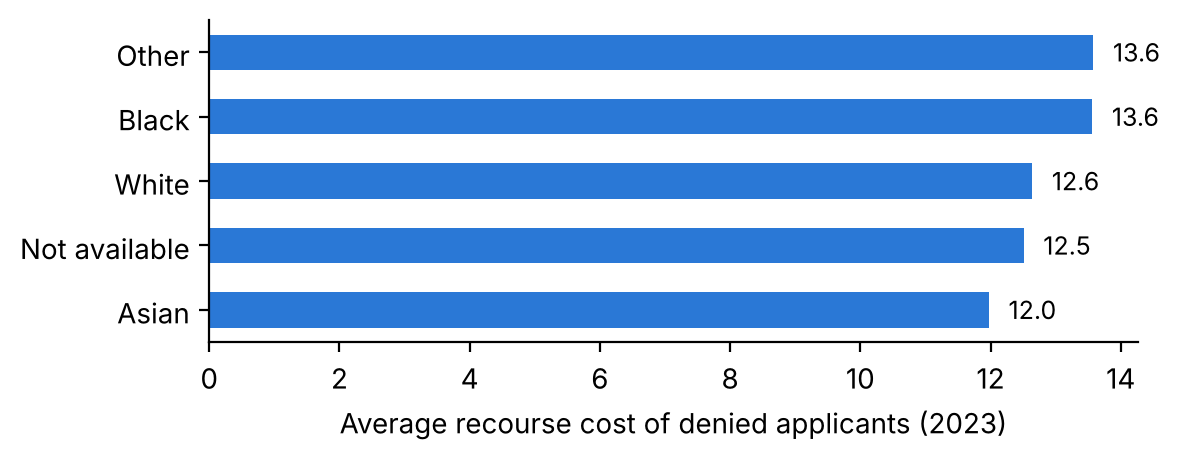

In [23]:
rc = rec[rec.attribute == "race"].set_index("group")["mean cost"].sort_values()
fig, ax = plt.subplots(figsize=(6, 2.4))
ax.barh(rc.index, rc.values, color=BLUE, height=0.55)
for i, v in enumerate(rc.values):
    ax.text(v + 0.3, i, f"{v:.1f}", va="center", fontsize=9)
ax.set_xlabel("Average recourse cost of denied applicants (2023)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 6. Results vs. the targets from Report 1

In [24]:
main = fair_policy[fair_policy.group.isin(["Black", "Asian", "Female", "Hispanic"])]
main_rec = rec[rec.group.isin(["Black", "Asian", "Female", "Hispanic"])]
ece_groups = fair_m2[~fair_m2.group.isin(["Other", "Other / n.a."])].ECE.max()
checks = [
    ("M2 beats rule baseline by >= 5 AUC points", perf.loc["M2 tree", "AUC"] - perf.loc["Baseline rule", "AUC"], ">= 0.05"),
    ("M2 within 3 AUC points of M1 (test)", perf.loc["M1 XGBoost", "AUC"] - perf.loc["M2 tree", "AUC"], "<= 0.03"),
    ("Calibration error, worst group (M2)", ece_groups, "<= 0.05"),
    ("Adverse impact ratio, worst group (policy)", main.AIR.min(), ">= 0.80"),
    ("Equal opportunity gap, worst group (policy)", main["EO gap"].max(), "<= 0.05"),
    ("Denials with feasible recourse", denied.feasible.mean(), ">= 0.90"),
    ("Recourse cost gap, worst group", main_rec["gap vs ref"].max(), "<= 0.10"),
    ("Decision flips in twin test (M2)", 0.0, "<= 0.01"),
    ("Temporal AUC drop (M2)", cv_tree[DEPTH] - perf.loc["M2 tree", "AUC"], "<= 0.03"),
]
def passed(v, t):
    op, lim = t.split()
    return v >= float(lim) if op == ">=" else v <= float(lim)
summary = pd.DataFrame([{"check": c, "value": round(v, 3), "target": t, "met": "yes" if passed(v, t) else "NO"}
                        for c, v, t in checks])
print(summary.to_string(index=False))

                                      check  value  target met
  M2 beats rule baseline by >= 5 AUC points  0.204 >= 0.05 yes
        M2 within 3 AUC points of M1 (test)  0.028 <= 0.03 yes
        Calibration error, worst group (M2)  0.059 <= 0.05  NO
 Adverse impact ratio, worst group (policy)  0.918 >= 0.80 yes
Equal opportunity gap, worst group (policy)  0.011 <= 0.05 yes
             Denials with feasible recourse  0.931 >= 0.90 yes
             Recourse cost gap, worst group  0.073 <= 0.10 yes
           Decision flips in twin test (M2)  0.000 <= 0.01 yes
                     Temporal AUC drop (M2) -0.025 <= 0.03 yes


## 7. Conclusions

* **Accuracy.** The depth-6 tree reaches about 0.835 AUC on 2023, far above the fixed underwriting
  rule (about 0.63) and less than 3 points below XGBoost. Depth 4, which I planned in Report 1, lost
  about 5 points in cross-validation, so I went to depth 6. Each decision still has at most 6 conditions.
* **Feature A.** The full set of requirements from Report 1 is unsatisfiable. clingo found two MUSes:
  the bank's 50% DTI cap clashes with the 85% accuracy target, and also with equal opportunity for
  Black applicants (a strict DTI cap rejects many Black applicants whom lenders actually approved).
  The minimal correction is to give up the DTI rule. Fairness can then be pushed to AIR >= 0.95 at a
  cost of about 0.6 accuracy points. AIR >= 0.97 is impossible because of Hispanic applicants alone.
* **Feature B.** About 93% of denied applicants get a concrete recourse, and every denial cites the
  exact rule behind it. Recourse is somewhat more expensive for Black applicants (about 7% above White),
  inside the 10% target but worth monitoring.
* **What failed.** Calibration for Black applicants (ECE about 0.06) misses the 0.05 target, so the
  score should not be read as a probability for this group without recalibration.
* **Limitations.** The label is the lender's past decision, not repayment, so "accuracy" partly
  means "agreeing with past bias". There is no credit score in public HMDA. DTI above 60% is a range,
  which I set to 65%, so "lower DTI to 60%" may understate the real effort. Applicants with missing
  data (more often denied, and more often Black) were dropped.